# Problema 2: Árboles que cortan en diagonal
**Alumno:** Owen Adiel Solis Zatarain
**Expediente / semilla:** `223201053` ($a = 3$, $b = 5$)

- Datos reales: $a \bmod 4 = 3$ → **vino tinto** (`winequality-red.csv`), clase 1 si la calidad es 7 o más.
- Ángulo de rotación del inciso (b): $10 + 5b = 35°$.

In [1]:
import io, zipfile, urllib.request, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import average_precision_score, roc_auc_score

SEMILLA = 223201053
A, B = 3, 5
ANGULO = 10 + 5 * B          # 35 grados
Path("figuras").mkdir(exist_ok=True)

---
## (a) Tu árbol

El árbol oblicuo sigue el pseudocódigo de la teoría (e). En cada nodo:
1. Calcula la **dirección de Fisher** $w = S_W^{-1}(m_1 - m_0)$ con los datos que llegan al nodo, proyecta los puntos ($w^\top x$) y busca el mejor umbral con el **índice de Gini**.
2. Busca también el mejor **corte paralelo** a cada eje.
3. Se queda con el corte de **menor Gini**. Si $S_W$ no es invertible, solo usa los cortes paralelos.

Para decidir si $S_W$ es invertible usamos el número de condición de $S_W$ **normalizada** (dividida entre $\sqrt{S_{ii} S_{jj}}$, como una matriz de correlación). En el vino, las variables tienen escalas muy distintas (la varianza de `density` es ~$10^{-6}$ y la de `total sulfur dioxide` ~$10^3$), y el número de condición "crudo" sale enorme solo por las unidades, aunque la matriz esté bien.

`oblicuo=False` convierte la clase en un árbol normal (solo cortes paralelos); lo usamos en el inciso (d) para comparar con el mismo código.

In [2]:
# ClassifierMixin va ANTES que BaseEstimator: si no, sklearn no lo reconoce como clasificador
# y los puntajes que usan predict_proba (AUC) fallan.
class ArbolOblicuo(ClassifierMixin, BaseEstimator):
    """Árbol de decisión binario con cortes oblicuos w^T x <= t.

    En cada nodo se calcula la dirección de Fisher w = S_W^{-1}(m1 - m0) y se compara
    su mejor corte contra el mejor corte paralelo a cada eje; se queda el de menor Gini.
    Si S_W no es invertible (número de condición de S_W normalizada > cond_max),
    el nodo solo usa cortes paralelos.

    oblicuo=False lo convierte en un árbol normal (solo cortes paralelos).
    """

    def __init__(self, max_depth=None, min_samples_split=2, oblicuo=True, cond_max=1e10):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.oblicuo = oblicuo
        self.cond_max = cond_max

    # ---------- entrenamiento ----------
    def fit(self, X, y):
        X, y = check_X_y(X, y)
        self.classes_, y01 = np.unique(y, return_inverse=True)
        if len(self.classes_) != 2:
            raise ValueError("ArbolOblicuo solo hace clasificación binaria")
        self.n_features_in_ = X.shape[1]
        self.n_hojas_ = 0
        self.n_cortes_oblicuos_ = 0
        self.arbol_ = self._construir(X, y01.astype(float), profundidad=0)
        return self

    @staticmethod
    def _mejor_umbral(z, y):
        """Mejor umbral sobre los valores proyectados z (Gini ponderado). Regresa (t, gini) o None."""
        orden = np.argsort(z, kind="stable")
        z, y = z[orden], y[orden]
        n = len(y)
        n_izq = np.arange(1, n)                  # el corte va entre el renglón i-1 e i
        pos_izq = np.cumsum(y)[:-1]
        n_der = n - n_izq
        pos_der = y.sum() - pos_izq
        p_izq, p_der = pos_izq / n_izq, pos_der / n_der
        gini = (n_izq * 2 * p_izq * (1 - p_izq) + n_der * 2 * p_der * (1 - p_der)) / n
        gini[z[1:] <= z[:-1]] = np.inf           # solo entre valores consecutivos distintos
        k = np.argmin(gini)
        if not np.isfinite(gini[k]):
            return None
        return (z[k] + z[k + 1]) / 2, gini[k]

    def _direccion_fisher(self, X, y):
        """w = S_W^{-1}(m1 - m0), o None si S_W no es invertible."""
        X0, X1 = X[y == 0], X[y == 1]
        if len(X0) < 2 or len(X1) < 2:
            return None
        m0, m1 = X0.mean(axis=0), X1.mean(axis=0)
        S_W = (X0 - m0).T @ (X0 - m0) + (X1 - m1).T @ (X1 - m1)
        escala = np.sqrt(np.diag(S_W))
        if np.any(escala == 0):                  # alguna variable constante dentro de las clases
            return None
        # Número de condición de S_W normalizada (como matriz de correlación): no depende de las unidades
        if np.linalg.cond(S_W / np.outer(escala, escala)) > self.cond_max:
            return None
        return np.linalg.solve(S_W, m1 - m0)

    def _construir(self, X, y, profundidad):
        n, d = X.shape
        p = y.mean()
        hoja = {"hoja": True, "p": p}
        if ((self.max_depth is not None and profundidad >= self.max_depth)
                or p in (0.0, 1.0) or n < self.min_samples_split):
            self.n_hojas_ += 1
            return hoja

        candidatos = []                          # (gini, tipo, w, t)
        if self.oblicuo:
            w = self._direccion_fisher(X, y)
            if w is not None:
                r = self._mejor_umbral(X @ w, y)
                if r is not None:
                    candidatos.append((r[1], "oblicuo", w, r[0]))
        for j in range(d):
            r = self._mejor_umbral(X[:, j], y)
            if r is not None:
                candidatos.append((r[1], "paralelo", np.eye(d)[j], r[0]))

        gini_nodo = 2 * p * (1 - p)
        if not candidatos:
            self.n_hojas_ += 1
            return hoja
        gini, tipo, w, t = min(candidatos, key=lambda c: c[0])
        if gini >= gini_nodo - 1e-12:            # ningún corte mejora el Gini
            self.n_hojas_ += 1
            return hoja

        self.n_cortes_oblicuos_ += tipo == "oblicuo"
        izq = X @ w <= t
        return {"hoja": False, "tipo": tipo, "w": w, "t": t,
                "izq": self._construir(X[izq], y[izq], profundidad + 1),
                "der": self._construir(X[~izq], y[~izq], profundidad + 1)}

    # ---------- predicción ----------
    def _proba_clase1(self, nodo, X, idx, salida):
        if nodo["hoja"]:
            salida[idx] = nodo["p"]
            return
        izq = X[idx] @ nodo["w"] <= nodo["t"]
        self._proba_clase1(nodo["izq"], X, idx[izq], salida)
        self._proba_clase1(nodo["der"], X, idx[~izq], salida)

    def predict_proba(self, X):
        check_is_fitted(self)
        X = check_array(X)
        p = np.empty(len(X))
        self._proba_clase1(self.arbol_, X, np.arange(len(X)), p)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return self.classes_[(self.predict_proba(X)[:, 1] >= 0.5).astype(int)]

    def get_n_leaves(self):
        check_is_fitted(self)
        return self.n_hojas_

**Prueba automática** con los seis puntos de la teoría (b): la dirección debe ser proporcional a la calculada a mano, $(2, -2) \propto (1, -1)$, y el nodo no debe tener errores.

In [3]:
# Prueba automática con los seis puntos del inciso (b) de la teoría
X_b = np.array([[0, 1], [1, 3], [3, 4], [1, 0], [3, 1], [4, 3]], dtype=float)
y_b = np.array([0, 0, 0, 1, 1, 1])

arbol_b = ArbolOblicuo(max_depth=1).fit(X_b, y_b)
raiz = arbol_b.arbol_
w_mano = np.array([1.0, -1.0])                  # dirección calculada a mano: (2, -2) ∝ (1, -1)
coseno = raiz["w"] @ w_mano / (np.linalg.norm(raiz["w"]) * np.linalg.norm(w_mano))

assert raiz["tipo"] == "oblicuo", "la raíz debería usar el corte oblicuo"
assert np.isclose(abs(coseno), 1.0), f"w = {raiz['w']} no es proporcional a (1, -1)"
assert np.allclose(raiz["w"], [2, -2]), f"w = {raiz['w']}, a mano dio (2, -2)"
assert (arbol_b.predict(X_b) == y_b).all(), "el nodo debería separar los seis puntos sin errores"
assert arbol_b.get_n_leaves() == 2
print(f"w = {raiz['w']}, umbral t = {raiz['t']:.3f}, exactitud en los 6 puntos = {arbol_b.score(X_b, y_b):.0%}")
print("Prueba superada: w ∝ (1, -1) y el nodo no tiene errores.")

w = [ 2. -2.], umbral t = -0.000, exactitud en los 6 puntos = 100%
Prueba superada: w ∝ (1, -1) y el nodo no tiene errores.


La dirección que encuentra el código es **exactamente** $(2, -2)$, la misma que calculamos a mano en la teoría (b), con umbral $t = 0$ y los seis puntos bien clasificados.

---
## (b) Girar y transformar

Generamos 1,000 puntos uniformes en $[-1, 1]^2$ con clase 1 si $x_1 > 0.2$, y armamos tres versiones de los datos: sin girar, girados 35° y sin girar con $x_1 \mapsto e^{3x_1}$.

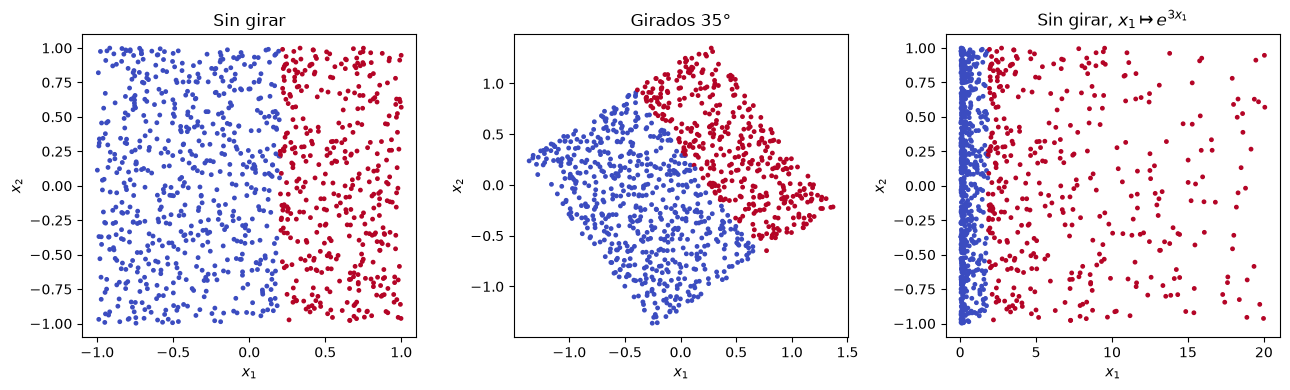

In [4]:
rng = np.random.default_rng(SEMILLA)
X_orig = rng.uniform(-1, 1, size=(1000, 2))
y_sint = (X_orig[:, 0] > 0.2).astype(int)

theta = np.deg2rad(ANGULO)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])
X_girado = X_orig @ R.T                          # cada punto girado 35° (la clase no cambia)

X_exp = X_orig.copy()
X_exp[:, 0] = np.exp(3 * X_orig[:, 0])           # x1 -> e^{3 x1}, sin girar

conjuntos_b = {"Sin girar": X_orig, f"Girados {ANGULO}°": X_girado, "Sin girar, $x_1 \\mapsto e^{3x_1}$": X_exp}

fig, ejes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (nombre, Xc) in zip(ejes, conjuntos_b.items()):
    ax.scatter(Xc[:, 0], Xc[:, 1], c=y_sint, s=6, cmap="coolwarm")
    ax.set_title(nombre)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
plt.tight_layout()
plt.savefig("figuras/datos_sinteticos.png", dpi=150)
plt.show()

La frontera real es una línea vertical en los datos sin girar, una línea inclinada 35° en los girados, y sigue siendo una línea vertical (en $e^{3 \cdot 0.2} \approx 1.82$) en los transformados con la exponencial, solo que con la escala de $x_1$ deformada.

In [5]:
PROFUNDIDADES = range(1, 9)
pliegues_b = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
modelos_b = {
    "Árbol oblicuo": lambda d: ArbolOblicuo(max_depth=d),
    "Árbol de sklearn": lambda d: DecisionTreeClassifier(max_depth=d, random_state=SEMILLA),
    "Bosque aleatorio": lambda d: RandomForestClassifier(n_estimators=100, max_depth=d,
                                                         random_state=SEMILLA, n_jobs=-1),
}
filas = []
for nombre_datos, Xc in conjuntos_b.items():
    for nombre_modelo, crear in modelos_b.items():
        for d in PROFUNDIDADES:
            exac = cross_val_score(crear(d), Xc, y_sint, cv=pliegues_b, scoring="accuracy")
            filas.append({"Datos": nombre_datos, "Modelo": nombre_modelo,
                          "Profundidad": d, "Exactitud": exac.mean()})
resultados_b = pd.DataFrame(filas)
tabla_b = resultados_b.pivot_table(index=["Datos", "Modelo"], columns="Profundidad",
                                   values="Exactitud").round(3)
tabla_b

Profundidad                                             1      2      3  \
Datos                             Modelo                                  
Girados 35°                       Bosque aleatorio  0.886  0.937  0.958   
                                  Árbol de sklearn  0.817  0.906  0.930   
                                  Árbol oblicuo     1.000  1.000  1.000   
Sin girar                         Bosque aleatorio  1.000  1.000  1.000   
                                  Árbol de sklearn  1.000  1.000  1.000   
                                  Árbol oblicuo     1.000  1.000  1.000   
Sin girar, $x_1 \mapsto e^{3x_1}$ Bosque aleatorio  1.000  1.000  1.000   
                                  Árbol de sklearn  1.000  1.000  1.000   
                                  Árbol oblicuo     1.000  1.000  1.000   

Profundidad                                             4      5      6  \
Datos                             Modelo                                  
Girados 35°                       Bosque aleatorio  0.976  0.984  0.988   
                                  Árbol de sklearn  0.960  0.979  0.983   
                                  Árbol oblicuo     1.000  1.000  1.000   
Sin girar                         Bosque aleatorio  1.000  1.000  1.000   
                                  Árbol de sklearn  1.000  1.000  1.000   
                                  Árbol oblicuo     1.000  1.000  1.000   
Sin girar, $x_1 \mapsto e^{3x_1}$ Bosque aleatorio  1.000  1.000  1.000   
                                  Árbol de sklearn  1.000  1.000  1.000   
                                  Árbol oblicuo     1.000  1.000  1.000   

Profundidad                                             7      8  
Datos                             Modelo                          
Girados 35°                       Bosque aleatorio  0.988  0.988  
                                  Árbol de sklearn  0.981  0.981  
                                  Árbol oblicuo     1.000  1.000  
Sin girar                         Bosque aleatorio  1.000  1.000  
                                  Árbol de sklearn  1.000  1.000  
                                  Árbol oblicuo     1.000  1.000  
Sin girar, $x_1 \mapsto e^{3x_1}$ Bosque aleatorio  1.000  1.000  
                                  Árbol de sklearn  1.000  1.000  
                                  Árbol oblicuo     1.000  1.000

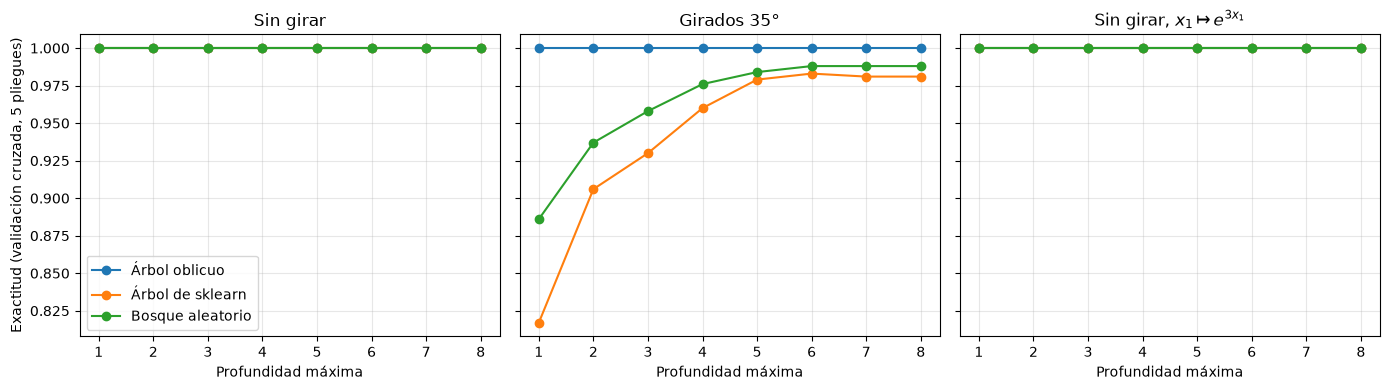

In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, nombre_datos in zip(ejes, conjuntos_b):
    sub = resultados_b[resultados_b["Datos"] == nombre_datos]
    for nombre_modelo, g in sub.groupby("Modelo", sort=False):
        ax.plot(g["Profundidad"], g["Exactitud"], marker="o", label=nombre_modelo)
    ax.set_title(nombre_datos)
    ax.set_xlabel("Profundidad máxima")
    ax.grid(alpha=0.3)
ejes[0].set_ylabel("Exactitud (validación cruzada, 5 pliegues)")
ejes[0].legend()
plt.tight_layout()
plt.savefig("figuras/rotacion_exactitud.png", dpi=150)
plt.show()

**Comentario.**
- **Sin girar**, los tres modelos tienen 100 % desde profundidad 1: la frontera $x_1 > 0.2$ es un solo corte vertical.
- **Girados 35°**, el árbol de `scikit-learn` cae a ~82 % con profundidad 1 y necesita una escalera de muchos cortes para acercarse a ~98 %; el bosque mejora un poco pero tampoco llega a 100 %. El **árbol oblicuo se queda en 100 % desde profundidad 1**: como probamos en la teoría (d), sus cortes no cambian al girar los datos, y con un solo corte oblicuo separa la frontera inclinada.
- **Con $x_1 \mapsto e^{3x_1}$** nadie cambia. Para el árbol de `scikit-learn` y el bosque es lo esperado: la exponencial es estrictamente creciente y sus cortes no cambian (teoría (d), parte 1). Para el árbol oblicuo, la teoría dice que **no** es invariante a una transformación no lineal, así que podría haber cambiado. No cambia porque la frontera sigue siendo una línea vertical ($e^{3x_1} > e^{0.6}$), y nuestro árbol compara el corte oblicuo contra el paralelo en cada nodo: elige el corte paralelo, que sí es invariante. Un árbol que usara *solo* cortes oblicuos sí podría verse afectado.

Coincide con la teoría (d): el árbol paralelo es invariante a funciones crecientes pero no a rotaciones, y el oblicuo es invariante a rotaciones.

---
## (c) Tus datos reales: vino tinto

**Decisiones (Tú decides).**
- **Métrica:** solo el 13.6 % de los vinos tiene calidad ≥ 7, así que la exactitud engaña (decir "malo" a todos da 86 %). Usamos **AUC-PR** (*average precision*) como métrica principal, porque mide qué tan bien el modelo pone a los vinos buenos hasta arriba y con desbalance es más exigente; su valor de azar es la proporción de positivos (0.136). Como complemento reportamos **AUC-ROC**.
- **Profundidad:** con **validación cruzada anidada**. Los 5 pliegues externos solo sirven para evaluar; dentro de cada uno, otra validación cruzada de 5 pliegues elige la profundidad (de 1 a 10) usando solo el entrenamiento. Así el número reportado no está inflado por elegir con los mismos datos con los que se evalúa (la lección del Problema 1).
- Bosque aleatorio con 200 árboles y bagging con 50 árboles oblicuos; en los dos se elige la profundidad de sus árboles.

In [7]:
URL_VINO = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"
zip_vino = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL_VINO).read()))
vino = pd.read_csv(zip_vino.open("winequality-red.csv"), sep=";")

X_vino = vino.drop(columns="quality").to_numpy()
y_vino = (vino["quality"] >= 7).astype(int).to_numpy()   # clase 1: calidad 7 o más
print(f"{len(vino)} vinos, {X_vino.shape[1]} variables; "
      f"{y_vino.sum()} de calidad >= 7 ({y_vino.mean():.1%})")

1599 vinos, 11 variables; 217 de calidad >= 7 (13.6%)


In [8]:
REJILLA_PROF = list(range(1, 11))
modelos_c = {
    "Árbol oblicuo": (ArbolOblicuo(), {"max_depth": REJILLA_PROF}),
    "Árbol de sklearn": (DecisionTreeClassifier(random_state=SEMILLA), {"max_depth": REJILLA_PROF}),
    "Bosque aleatorio": (RandomForestClassifier(n_estimators=200, random_state=SEMILLA, n_jobs=-1),
                         {"max_depth": REJILLA_PROF}),
    "Bagging de árboles oblicuos": (BaggingClassifier(ArbolOblicuo(), n_estimators=50,
                                                      random_state=SEMILLA, n_jobs=-1),
                                    {"estimator__max_depth": REJILLA_PROF}),
}


def hojas_promedio(modelo):
    """Hojas del árbol, o promedio de hojas por árbol en un ensamble."""
    if hasattr(modelo, "estimators_"):
        return np.mean([e.get_n_leaves() for e in modelo.estimators_])
    return modelo.get_n_leaves()


externos = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)       # para evaluar
internos = StratifiedKFold(5, shuffle=True, random_state=SEMILLA + 1)   # para elegir la profundidad

filas_c = []
for nombre, (modelo, rejilla) in modelos_c.items():
    for i, (i_ent, i_pru) in enumerate(externos.split(X_vino, y_vino)):
        busqueda = GridSearchCV(modelo, rejilla, cv=internos, scoring="average_precision", n_jobs=-1)
        busqueda.fit(X_vino[i_ent], y_vino[i_ent])           # la profundidad se elige solo con el entrenamiento
        prob = busqueda.predict_proba(X_vino[i_pru])[:, 1]
        filas_c.append({
            "Modelo": nombre, "Pliegue": i,
            "Profundidad": list(busqueda.best_params_.values())[0],
            "AUC-PR": average_precision_score(y_vino[i_pru], prob),
            "AUC-ROC": roc_auc_score(y_vino[i_pru], prob),
            "Hojas": hojas_promedio(busqueda.best_estimator_),
            "Tiempo (s)": busqueda.refit_time_,                # entrenar el modelo final con esa profundidad
        })
resultados_c = pd.DataFrame(filas_c)

tabla_c = resultados_c.groupby("Modelo", sort=False).agg(
    **{"AUC-PR": ("AUC-PR", "mean"), "AUC-PR (desv.)": ("AUC-PR", "std"),
       "AUC-ROC": ("AUC-ROC", "mean"), "AUC-ROC (desv.)": ("AUC-ROC", "std"),
       "Profundidades elegidas": ("Profundidad", lambda s: ", ".join(map(str, s))),
       "Hojas (por árbol)": ("Hojas", "mean"), "Tiempo de entrenamiento (s)": ("Tiempo (s)", "mean")}
).round(3)
print(f"Tasa base de AUC-PR (proporción de positivos): {y_vino.mean():.3f}")
tabla_c

Tasa base de AUC-PR (proporción de positivos): 0.136


,AUC-PR,AUC-PR (desv.),AUC-ROC,AUC-ROC (desv.),Profundidades elegidas,Hojas (por árbol),Tiempo de entrenamiento (s)
Modelo,,,,,,,
Árbol oblicuo,0.435,0.031,0.837,0.040,"4, 3, 2, 5, 3",11.600,0.005
Árbol de sklearn,0.503,0.076,0.834,0.035,"5, 4, 4, 3, 4",17.200,0.002
Bosque aleatorio,0.744,0.036,0.929,0.009,"10, 10, 9, 10, 10",88.802,0.201
Bagging de árboles oblicuos,0.737,0.054,0.923,0.013,"10, 10, 9, 10, 9",55.064,0.186


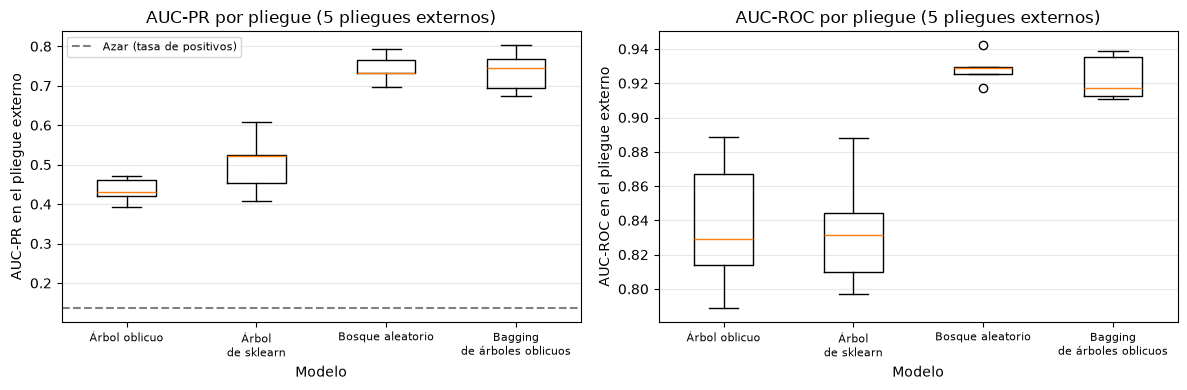

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica in zip(ejes, ["AUC-PR", "AUC-ROC"]):
    datos = [resultados_c.loc[resultados_c["Modelo"] == m, metrica] for m in modelos_c]
    ax.boxplot(datos)
    ax.set_xticks(range(1, len(modelos_c) + 1), [m.replace(" de ", "\nde ") for m in modelos_c], fontsize=8)
    ax.set_ylabel(f"{metrica} en el pliegue externo")
    ax.set_xlabel("Modelo")
    ax.grid(alpha=0.3, axis="y")
ejes[0].axhline(y_vino.mean(), color="gray", ls="--", label="Azar (tasa de positivos)")
ejes[0].legend(fontsize=8)
ejes[0].set_title("AUC-PR por pliegue (5 pliegues externos)")
ejes[1].set_title("AUC-ROC por pliegue (5 pliegues externos)")
plt.tight_layout()
plt.savefig("figuras/vino_comparacion.png", dpi=150)
plt.show()

**Comentario.**
- Todos los modelos están muy por encima del azar (AUC-PR de 0.136).
- **Árbol oblicuo contra árbol de `scikit-learn`:** empatan en AUC-ROC (~0.84), pero el árbol oblicuo **pierde en AUC-PR** (0.435 contra 0.503), es decir, ordena peor a los vinos de arriba, que son los que más importan con clases desbalanceadas. A cambio usa menos hojas (~12 contra ~17).
- **Ensambles:** el bosque aleatorio y el **bagging de árboles oblicuos** son por mucho los mejores (AUC-PR ~0.74, AUC-ROC ~0.93) y están prácticamente empatados; la diferencia entre ellos es menor que su variación entre pliegues. El bagging sube al árbol oblicuo de 0.435 a 0.737.
- **Tiempo:** los árboles solos tardan milisegundos; los ensambles, ~0.2 s, porque entrenan 50 o 200 árboles. Nuestro árbol está escrito en Python puro y aun así es rápido con 1,599 datos.
- Las profundidades elegidas varían entre pliegues (de 2 a 5 en los árboles solos), una señal de que la elección es ruidosa con pocos vinos buenos.

---
## (d) Cuándo vale la pena

**Hipótesis.** El árbol oblicuo perdió por **varianza**: cada corte oblicuo estima 11 pesos con los datos del nodo, y en los nodos profundos quedan pocos vinos buenos, así que la dirección de Fisher se ajusta al ruido (la teoría (c): más cortes posibles, más riesgo de sobreajustar). **Hipótesis alternativa:** perdió porque varias variables tienen colas largas y la dirección de Fisher, que usa medias y covarianzas, es sensible a valores extremos.

**Experimento.** Comparamos, por profundidad, el AUC-PR en entrenamiento y en validación de (1) el árbol oblicuo, (2) el **mismo código con `oblicuo=False`** (solo cortes paralelos, para que la única diferencia sea el tipo de corte) y (3) el árbol oblicuo con $\log(1 + x)$ en todas las variables.

In [10]:
# Hipótesis: el árbol oblicuo pierde por VARIANZA. Cada corte oblicuo estima 11 pesos (la
# dirección de Fisher) con los datos del nodo; en nodos profundos quedan pocos vinos buenos y
# esa dirección se ajusta al ruido. Un corte paralelo solo elige 1 variable y 1 umbral.
# Predicción: el oblicuo debe tener MAYOR puntaje en entrenamiento pero MENOR en validación
# conforme crece la profundidad, y promediar muchos árboles (bagging) debe corregirlo.
#
# Hipótesis alternativa: pierde porque varias variables tienen colas largas (asimetría alta),
# y las medias y S_W de Fisher son sensibles a valores extremos. Si fuera esto, aplicar log
# a las variables debería ayudar al oblicuo (el árbol paralelo no cambia: inciso (d) de la teoría).
from sklearn.model_selection import cross_validate

pliegues_d = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
X_vino_log = np.log1p(X_vino)
variantes_d = {
    "Oblicuo": (lambda d: ArbolOblicuo(max_depth=d), X_vino),
    "Solo cortes paralelos (mismo código, oblicuo=False)": (lambda d: ArbolOblicuo(max_depth=d, oblicuo=False), X_vino),
    "Oblicuo con log(1 + x)": (lambda d: ArbolOblicuo(max_depth=d), X_vino_log),
}
filas_d = []
for nombre, (crear, Xc) in variantes_d.items():
    for d in REJILLA_PROF:
        r = cross_validate(crear(d), Xc, y_vino, cv=pliegues_d, scoring="average_precision",
                           return_train_score=True)
        filas_d.append({"Variante": nombre, "Profundidad": d,
                        "AUC-PR entrenamiento": r["train_score"].mean(),
                        "AUC-PR validación": r["test_score"].mean()})
resultados_d = pd.DataFrame(filas_d)
print("Asimetría de las variables:", vino.drop(columns="quality").skew().round(1).to_dict())
resultados_d.pivot_table(index="Profundidad", columns="Variante",
                         values=["AUC-PR entrenamiento", "AUC-PR validación"]).round(3)

Asimetría de las variables: {'fixed acidity': 1.0, 'volatile acidity': 0.7, 'citric acid': 0.3, 'residual sugar': 4.5, 'chlorides': 5.7, 'free sulfur dioxide': 1.3, 'total sulfur dioxide': 1.5, 'density': 0.1, 'pH': 0.2, 'sulphates': 2.4, 'alcohol': 0.9}


AUC-PR entrenamiento                         \
Variante                 Oblicuo Oblicuo con log(1 + x)   
Profundidad                                               
1                          0.368                  0.380   
2                          0.468                  0.486   
3                          0.553                  0.582   
4                          0.662                  0.697   
5                          0.775                  0.802   
6                          0.863                  0.870   
7                          0.919                  0.920   
8                          0.952                  0.956   
9                          0.973                  0.979   
10                         0.988                  0.992   

                                                                 \
Variante    Solo cortes paralelos (mismo código, oblicuo=False)   
Profundidad                                                       
1                                                        0.291    
2                                                        0.424    
3                                                        0.531    
4                                                        0.641    
5                                                        0.747    
6                                                        0.839    
7                                                        0.895    
8                                                        0.933    
9                                                        0.962    
10                                                       0.978    

            AUC-PR validación                         \
Variante              Oblicuo Oblicuo con log(1 + x)   
Profundidad                                            
1                       0.343                  0.340   
2                       0.397                  0.408   
3                       0.444                  0.448   
4                       0.449                  0.450   
5                       0.454                  0.434   
6                       0.449                  0.418   
7                       0.449                  0.390   
8                       0.409                  0.389   
9                       0.396                  0.357   
10                      0.394                  0.350   

                                                                 
Variante    Solo cortes paralelos (mismo código, oblicuo=False)  
Profundidad                                                      
1                                                        0.277   
2                                                        0.393   
3                                                        0.465   
4                                                        0.508   
5                                                        0.529   
6                                                        0.488   
7                                                        0.443   
8                                                        0.448   
9                                                        0.429   
10                                                       0.412

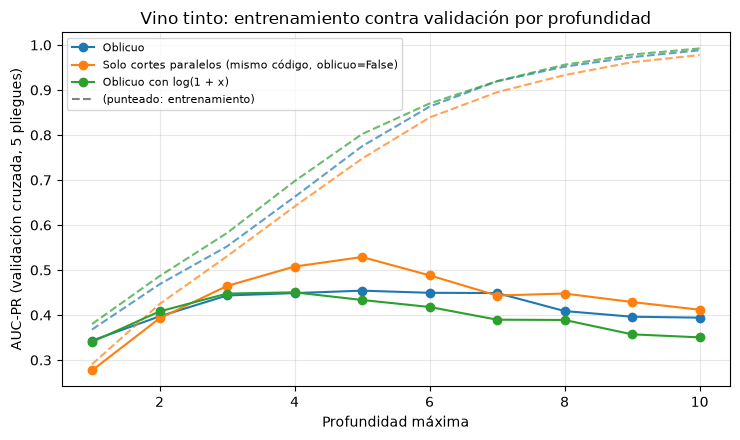

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
colores = {"Oblicuo": "tab:blue", "Solo cortes paralelos (mismo código, oblicuo=False)": "tab:orange",
           "Oblicuo con log(1 + x)": "tab:green"}
for nombre, g in resultados_d.groupby("Variante", sort=False):
    ax.plot(g["Profundidad"], g["AUC-PR entrenamiento"], ls="--", color=colores[nombre], alpha=0.7)
    ax.plot(g["Profundidad"], g["AUC-PR validación"], marker="o", color=colores[nombre], label=nombre)
ax.plot([], [], ls="--", color="gray", label="(punteado: entrenamiento)")
ax.set_xlabel("Profundidad máxima")
ax.set_ylabel("AUC-PR (validación cruzada, 5 pliegues)")
ax.set_title("Vino tinto: entrenamiento contra validación por profundidad")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figuras/vino_varianza.png", dpi=150)
plt.show()

**Comentario y conclusión.**
- Primero, una comprobación: nuestro árbol con `oblicuo=False` da casi lo mismo que el `DecisionTreeClassifier` de `scikit-learn` (por ejemplo, ~0.28 con profundidad 1 y ~0.39 con profundidad 2), así que la parte de cortes paralelos está bien programada.
- **Varianza confirmada.** En entrenamiento (líneas punteadas) el árbol oblicuo siempre queda **por encima** del paralelo: sus cortes son más flexibles y se ajustan mejor. Pero en validación (líneas sólidas), a partir de profundidad 3 queda **por debajo**: el paralelo llega a ~0.53 con profundidad 5 y el oblicuo se estanca en ~0.45. Ajustar mejor el entrenamiento y generalizar peor es la firma del sobreajuste. Con profundidad 1–2, en cambio, el oblicuo **gana** (0.34 contra 0.28 con profundidad 1): en la raíz hay muchos datos y la dirección de Fisher está bien estimada.
- **La hipótesis alternativa no se sostiene:** con $\log(1 + x)$ el árbol oblicuo no mejora; con profundidades grandes queda incluso peor.
- **El bagging lo confirma:** promediar 50 árboles oblicuos reduce la varianza y sube el AUC-PR de 0.435 a 0.737 (inciso (c)), al nivel del bosque aleatorio.

**¿Cuándo esperamos que gane el árbol oblicuo?** Cuando la frontera real es una **combinación lineal** de las variables (como los datos girados del inciso (b)) y hay **suficientes datos por nodo** para estimar la dirección; ahí resuelve con un corte lo que el árbol normal hace con una escalera. **¿Cuándo esperamos que pierda?** Cuando la frontera depende de pocas variables por separado o de umbrales en variables individuales, cuando hay pocos datos (sobre todo de la clase minoritaria) en los nodos profundos, o con muchas variables irrelevantes: cada corte oblicuo estima un peso por variable, y con poca información se ajusta al ruido. En esos casos conviene usarlo en un ensamble (bagging) o limitar su profundidad.